# 02 Main effects (H1)

Does emailing work? This notebook follows H1 in `analysis_plan.md`, which was committed before any of these numbers were calculated.

- Primary outcome: `visit`. Primary comparisons: Mens vs control and Womens vs control, with a Holm correction.
- Secondary outcomes: `conversion` and `spend` (unadjusted p-values).
- Estimators: difference in means (confirmatory), Lin regression adjustment, CUPED for spend, permutation tests, bootstrap and winsorizing for spend.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from helpers import load_data, diff_in_means, lin_regression, permutation_test, bootstrap_ci, holm

df = load_data()

control = df[df["segment"] == "No E-Mail"]
mens = df[df["segment"] == "Mens E-Mail"]
womens = df[df["segment"] == "Womens E-Mail"]

covariates = ["recency", "history", "mens", "womens", "newbie", "zip_urban", "zip_suburban", "channel_web", "channel_multi"]
outcomes = ["visit", "conversion", "spend"]

print("Control:", len(control), " Mens:", len(mens), " Womens:", len(womens))

Control: 21306  Mens: 21307  Womens: 21387


## 1. Difference in means

diff = mean_T - mean_C, SE = sqrt(s²_T / n_T + s²_C / n_C), 95% CI = diff ± 1.96 SE, p-value from the normal distribution.

In [2]:
rows = []
for arm_name in ["Mens E-Mail", "Womens E-Mail"]:
    treat = df[df["segment"] == arm_name]
    for outcome in outcomes:
        diff, se = diff_in_means(treat[outcome], control[outcome])
        p = 2 * (1 - stats.norm.cdf(abs(diff / se)))
        role = "secondary"
        if outcome == "visit":
            role = "primary"
        rows.append({
            "arm": arm_name,
            "outcome": outcome,
            "role": role,
            "n_treat": len(treat),
            "n_control": len(control),
            "control_mean": control[outcome].mean(),
            "treat_mean": treat[outcome].mean(),
            "diff": diff,
            "se": se,
            "z": diff / se,
            "ci_low": diff - 1.96 * se,
            "ci_high": diff + 1.96 * se,
            "p_value": p,
        })

results = pd.DataFrame(rows)
results.round(5)

,arm,outcome,role,n_treat,n_control,control_mean,treat_mean,diff,se,z,ci_low,ci_high,p_value
0,Mens E-Mail,visit,primary,21307,21306,0.10617,0.18276,0.07659,0.00339,22.62023,0.06995,0.08323,0.00000
1,Mens E-Mail,conversion,secondary,21307,21306,0.00573,0.01253,0.00681,0.00092,7.38974,0.00500,0.00861,0.00000
2,Mens E-Mail,spend,secondary,21307,21306,0.65279,1.42262,0.76983,0.14525,5.30014,0.48514,1.05451,0.00000
3,Womens E-Mail,visit,primary,21387,21306,0.10617,0.15140,0.04523,0.00323,13.98474,0.03889,0.05157,0.00000
4,Womens E-Mail,conversion,secondary,21387,21306,0.00573,0.00884,0.00311,0.00082,3.78163,0.00150,0.00472,0.00016
5,Womens E-Mail,spend,secondary,21387,21306,0.65279,1.07720,0.42441,0.13033,3.25637,0.16896,0.67986,0.00113


In [3]:
for i in range(len(results)):
    row = results.iloc[i]
    lift = row["diff"] / row["control_mean"] * 100
    print(row["arm"], row["outcome"], " diff:", round(row["diff"], 4), " relative lift:", round(lift, 1), "%")

Mens E-Mail visit  diff: 0.0766  relative lift: 72.1 %
Mens E-Mail conversion  diff: 0.0068  relative lift: 118.8 %
Mens E-Mail spend  diff: 0.7698  relative lift: 117.9 %
Womens E-Mail visit  diff: 0.0452  relative lift: 42.6 %
Womens E-Mail conversion  diff: 0.0031  relative lift: 54.3 %
Womens E-Mail spend  diff: 0.4244  relative lift: 65.0 %


## 2. Regression adjustment (Lin 2013)

Regress Y on the treatment dummy, the centered covariates and treatment × centered covariates, using only the two arms being compared, with HC2 SEs. Centering makes the treatment coefficient the ATE. Covariates soak up outcome variance that has nothing to do with treatment, so the SE should drop.

In [4]:
lin_diffs = []
lin_ses = []
for i in range(len(results)):
    arm_name = results.loc[i, "arm"]
    outcome = results.loc[i, "outcome"]
    sample = df[df["segment"].isin([arm_name, "No E-Mail"])].copy()
    sample["treat"] = (sample["segment"] == arm_name).astype(int)
    est, se = lin_regression(sample, outcome, "treat", covariates)
    lin_diffs.append(est)
    lin_ses.append(se)

results["lin_diff"] = lin_diffs
results["lin_se"] = lin_ses
results["lin_p_value"] = 2 * (1 - stats.norm.cdf(np.abs(results["lin_diff"] / results["lin_se"])))
results["lin_se_reduction_pct"] = (1 - results["lin_se"] / results["se"]) * 100
results[["arm", "outcome", "diff", "se", "lin_diff", "lin_se", "lin_se_reduction_pct"]].round(5)

,arm,outcome,diff,se,lin_diff,lin_se,lin_se_reduction_pct
0,Mens E-Mail,visit,0.07659,0.00339,0.07606,0.00334,1.48185
1,Mens E-Mail,conversion,0.00681,0.00092,0.00677,0.00092,0.14230
2,Mens E-Mail,spend,0.76983,0.14525,0.76689,0.14507,0.12383
3,Womens E-Mail,visit,0.04523,0.00323,0.04541,0.00319,1.43469
4,Womens E-Mail,conversion,0.00311,0.00082,0.00311,0.00082,0.10737
5,Womens E-Mail,spend,0.42441,0.13033,0.42466,0.13022,0.08380


## 3. CUPED for spend

θ = Cov(spend, history) / Var(history) on the pooled sample. Adjusted spend = spend − θ · (history − mean history). Because history is measured before the email, subtracting it does not change the expected difference between arms, but it removes the part of spend explained by past spending.

The variance of the adjusted outcome is Var(spend) · (1 − ρ²), where ρ is the correlation between spend and history.

In [5]:
theta = np.cov(df["spend"], df["history"])[0, 1] / df["history"].var()
rho = np.corrcoef(df["spend"], df["history"])[0, 1]
df["spend_cuped"] = df["spend"] - theta * (df["history"] - df["history"].mean())

print("theta:", round(theta, 5))
print("Correlation between spend and history:", round(rho, 4))
print("Expected variance reduction:", round(rho ** 2 * 100, 2), "%")

control = df[df["segment"] == "No E-Mail"]
mens = df[df["segment"] == "Mens E-Mail"]
womens = df[df["segment"] == "Womens E-Mail"]

cuped_mens, cuped_mens_se = diff_in_means(mens["spend_cuped"], control["spend_cuped"])
cuped_womens, cuped_womens_se = diff_in_means(womens["spend_cuped"], control["spend_cuped"])

results["cuped_diff"] = np.nan
results["cuped_se"] = np.nan
results.loc[(results["arm"] == "Mens E-Mail") & (results["outcome"] == "spend"), "cuped_diff"] = cuped_mens
results.loc[(results["arm"] == "Mens E-Mail") & (results["outcome"] == "spend"), "cuped_se"] = cuped_mens_se
results.loc[(results["arm"] == "Womens E-Mail") & (results["outcome"] == "spend"), "cuped_diff"] = cuped_womens
results.loc[(results["arm"] == "Womens E-Mail") & (results["outcome"] == "spend"), "cuped_se"] = cuped_womens_se
results["cuped_se_reduction_pct"] = (1 - results["cuped_se"] / results["se"]) * 100

results.loc[results["outcome"] == "spend", ["arm", "diff", "se", "cuped_diff", "cuped_se", "cuped_se_reduction_pct"]].round(5)

theta: 0.00128
Correlation between spend and history: 0.0217
Expected variance reduction: 0.05 %


,arm,diff,se,cuped_diff,cuped_se,cuped_se_reduction_pct
2,Mens E-Mail,0.76983,0.14525,0.76734,0.14522,0.02165
5,Womens E-Mail,0.42441,0.13033,0.42230,0.13031,0.01784


## 4. Randomization inference (permutation tests)

Under the sharp null that the email changed nobody's outcome, the arm labels are just random tags. So we reshuffle the labels 10,000 times within the two arms being compared, recompute the difference each time, and count how often the reshuffled difference is at least as extreme as the real one. Run for visit (primary) and spend (secondary).

In [6]:
np.random.seed(2026)
results["perm_p_value"] = np.nan
for i in range(len(results)):
    outcome = results.loc[i, "outcome"]
    if outcome == "conversion":
        continue
    treat = df[df["segment"] == results.loc[i, "arm"]]
    perm_p = permutation_test(treat[outcome].values, control[outcome].values, 10000)
    results.loc[i, "perm_p_value"] = perm_p
    print(results.loc[i, "arm"], outcome, " permutation p:", round(perm_p, 5))

Mens E-Mail visit  permutation p: 0.0001


Mens E-Mail spend  permutation p: 0.0001


Womens E-Mail visit  permutation p: 0.0001


Womens E-Mail spend  permutation p: 0.0008


## 5. Holm correction for the two primary tests

Sort the two p-values. The smaller one is compared with 0.05 / 2 and the larger one with 0.05. Adjusted p-values: p_(1) × 2, then max of that and p_(2).

In [7]:
primary = results[results["role"] == "primary"]
holm_p = holm(primary["p_value"].values)
holm_perm_p = holm(primary["perm_p_value"].values)

results["holm_p_value"] = np.nan
results["holm_perm_p_value"] = np.nan
results.loc[primary.index, "holm_p_value"] = holm_p
results.loc[primary.index, "holm_perm_p_value"] = holm_perm_p

results.loc[primary.index, ["arm", "outcome", "diff", "p_value", "holm_p_value", "perm_p_value", "holm_perm_p_value"]]

,arm,outcome,diff,p_value,holm_p_value,perm_p_value,holm_perm_p_value
0,Mens E-Mail,visit,0.076590,0.0,0.0,0.0001,0.0002
3,Womens E-Mail,visit,0.045233,0.0,0.0,0.0001,0.0002


## 6. Spend: bootstrap CI and winsorized robustness check

Spend is 99% zeros with a long right tail, so the normal approximation may be poor. The percentile bootstrap resamples customers within each arm 2,000 times.

Winsorizing: spend above the 95th percentile of positive pooled spend is set equal to that value (see `decisions_log.md` for why not the 99th).

In [8]:
np.random.seed(2026)
boot_mens_low, boot_mens_high = bootstrap_ci(mens["spend"].values, control["spend"].values, 2000)
boot_womens_low, boot_womens_high = bootstrap_ci(womens["spend"].values, control["spend"].values, 2000)
print("Mens spend bootstrap 95% CI:", round(boot_mens_low, 4), "to", round(boot_mens_high, 4))
print("Womens spend bootstrap 95% CI:", round(boot_womens_low, 4), "to", round(boot_womens_high, 4))

Mens spend bootstrap 95% CI: 0.4856 to 1.0372
Womens spend bootstrap 95% CI: 0.1802 to 0.6892


In [9]:
cap = df.loc[df["spend"] > 0, "spend"].quantile(0.95)
df["spend_wins"] = df["spend"].clip(upper=cap)
print("Winsorizing cap:", round(cap, 2))
print("Buyers above the cap:", (df["spend"] > cap).sum())

control = df[df["segment"] == "No E-Mail"]
mens = df[df["segment"] == "Mens E-Mail"]
womens = df[df["segment"] == "Womens E-Mail"]

wins_mens, wins_mens_se = diff_in_means(mens["spend_wins"], control["spend_wins"])
wins_womens, wins_womens_se = diff_in_means(womens["spend_wins"], control["spend_wins"])
print("Mens winsorized diff:", round(wins_mens, 4), " SE:", round(wins_mens_se, 4))
print("Womens winsorized diff:", round(wins_womens, 4), " SE:", round(wins_womens_se, 4))

Winsorizing cap: 362.2
Buyers above the cap: 28
Mens winsorized diff: 0.7374  SE: 0.1342
Womens winsorized diff: 0.4135  SE: 0.1214


In [10]:
mens_spend = (results["arm"] == "Mens E-Mail") & (results["outcome"] == "spend")
womens_spend = (results["arm"] == "Womens E-Mail") & (results["outcome"] == "spend")

results["boot_ci_low"] = np.nan
results["boot_ci_high"] = np.nan
results["wins_diff"] = np.nan
results["wins_se"] = np.nan
results.loc[mens_spend, "boot_ci_low"] = boot_mens_low
results.loc[mens_spend, "boot_ci_high"] = boot_mens_high
results.loc[womens_spend, "boot_ci_low"] = boot_womens_low
results.loc[womens_spend, "boot_ci_high"] = boot_womens_high
results.loc[mens_spend, "wins_diff"] = wins_mens
results.loc[mens_spend, "wins_se"] = wins_mens_se
results.loc[womens_spend, "wins_diff"] = wins_womens
results.loc[womens_spend, "wins_se"] = wins_womens_se

## 7. Exploratory: Mens email vs Womens email

**Exploratory.** This comparison is not in the analysis plan. It only describes which email did better on each outcome.

In [11]:
for outcome in outcomes:
    diff, se = diff_in_means(mens[outcome], womens[outcome])
    p = 2 * (1 - stats.norm.cdf(abs(diff / se)))
    print("Mens minus Womens,", outcome, ":", round(diff, 4), " 95% CI:", round(diff - 1.96 * se, 4), "to", round(diff + 1.96 * se, 4), " p:", round(p, 4))

Mens minus Womens, visit : 0.0314  95% CI: 0.0243 to 0.0384  p: 0.0
Mens minus Womens, conversion : 0.0037  95% CI: 0.0017 to 0.0056  p: 0.0002
Mens minus Womens, spend : 0.3454  95% CI: 0.0326 to 0.6583  p: 0.0305


## 8. Results table and chart

In [12]:
results = results.round(6)
results.to_csv("results/main_effects.csv", index=False)
results[["arm", "outcome", "role", "control_mean", "treat_mean", "diff", "ci_low", "ci_high", "z", "p_value", "holm_p_value", "lin_se_reduction_pct"]]

,arm,outcome,role,control_mean,treat_mean,diff,ci_low,ci_high,z,p_value,holm_p_value,lin_se_reduction_pct
0,Mens E-Mail,visit,primary,0.106167,0.182757,0.076590,0.069953,0.083226,22.620231,0.000000,0.0,1.481852
1,Mens E-Mail,conversion,secondary,0.005726,0.012531,0.006805,0.005000,0.008610,7.389736,0.000000,NaN,0.142298
2,Mens E-Mail,spend,secondary,0.652789,1.422617,0.769827,0.485144,1.054510,5.300140,0.000000,NaN,0.123829
3,Womens E-Mail,visit,primary,0.106167,0.151400,0.045233,0.038894,0.051573,13.984738,0.000000,0.0,1.434691
4,Womens E-Mail,conversion,secondary,0.005726,0.008837,0.003111,0.001499,0.004724,3.781627,0.000156,NaN,0.107369
5,Womens E-Mail,spend,secondary,0.652789,1.077202,0.424412,0.168960,0.679865,3.256372,0.001128,NaN,0.083798


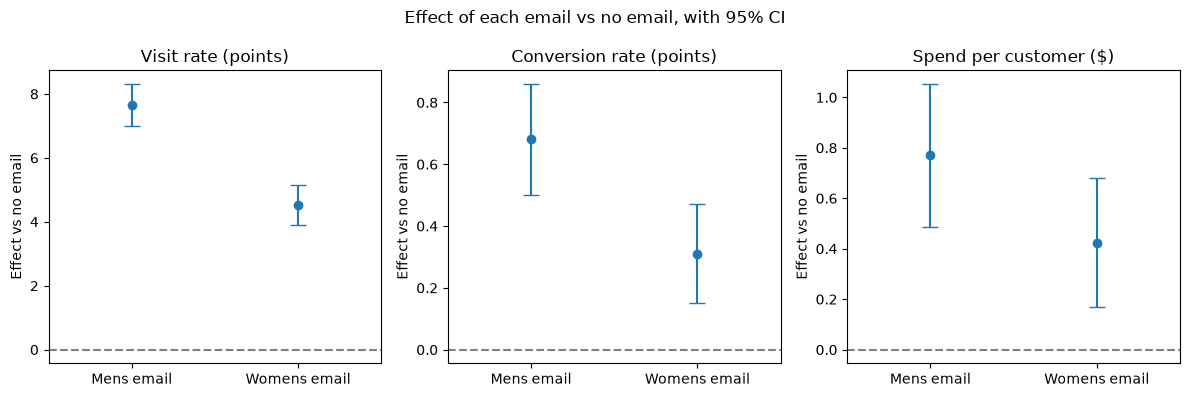

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = {"visit": "Visit rate (points)", "conversion": "Conversion rate (points)", "spend": "Spend per customer ($)"}
for j in range(3):
    outcome = outcomes[j]
    part = results[results["outcome"] == outcome]
    scale = 1
    if outcome != "spend":
        scale = 100
    est = part["diff"].values * scale
    low = part["ci_low"].values * scale
    high = part["ci_high"].values * scale
    axes[j].errorbar([0, 1], est, yerr=[est - low, high - est], fmt="o", capsize=6)
    axes[j].axhline(0, color="grey", linestyle="--")
    axes[j].set_xticks([0, 1])
    axes[j].set_xticklabels(["Mens email", "Womens email"])
    axes[j].set_xlim(-0.5, 1.5)
    axes[j].set_title(titles[outcome])
    axes[j].set_ylabel("Effect vs no email")
fig.suptitle("Effect of each email vs no email, with 95% CI")
plt.tight_layout()
plt.savefig("figures/main_effects.png", dpi=150)
plt.show()

## Summary

**Confirmatory (primary, visit):**

- The Mens email raised the 2-week visit rate from 10.6% to 18.3%, a gain of **7.7 percentage points** (95% CI 7.0 to 8.3, z = 22.6).
- The Womens email raised it to 15.1%, a gain of **4.5 points** (95% CI 3.9 to 5.2, z = 14.0).
- Both effects survive the Holm correction, with p-values far below 0.001. The permutation p-values are 0.0001, the smallest possible with 10,000 reshuffles: not one reshuffle came close to the real difference.

**Secondary:**

- Conversion: +0.68 points for Mens (0.57% to 1.25%) and +0.31 points for Womens (p = 0.0002).
- Spend per customer: **+$0.77 for Mens** (bootstrap CI $0.49 to $1.04) and **+$0.42 for Womens** (bootstrap CI $0.18 to $0.69). The bootstrap CIs are almost the same as the normal CIs.
- Winsorizing spend at $362 barely changes the answer ($0.74 and $0.41), so the result is not driven by a few big buyers.

**Variance reduction bought almost nothing here:**

- Lin regression adjustment cut the SE by about 1.5% for visit and 0.1% for spend. CUPED cut it by 0.02%.
- The reason: past-year spend (`history`) has a correlation of only 0.02 with 2-week spend. CUPED's variance reduction is ρ², so it can only help when the pre-period covariate strongly predicts the outcome, for example the same metric measured in a comparable earlier window. This is a useful lesson, not a failure: the method was pre-registered and reported as it came out.

**Exploratory:** the Mens email beat the Womens email on all three outcomes: +3.1 visit points (CI 2.4 to 3.8), +0.37 conversion points (CI 0.17 to 0.56) and +$0.35 spend (CI $0.03 to $0.66, much less precise). This was not a planned test, so it is only descriptive.